# Task 2 — Detailed Exploratory Data Analysis (Player Segmentation)

**Problem**: 4-class classification (`segment` $\in \{0, 1, 2, 3\}$), evaluated by **Macro $F_1$ score**.

This notebook presents a visual, step-by-step exploration of the data and explains why **EM Label-Noise-Aware Histogram Naive Bayes** (blended with Spline Logistic Regression and MLP + an affine Macro-$F_1$ decision rule) is the optimal architecture in `task2.ipynb`.

In [1]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, f_oneway

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

def find_data_dir(subdir: str) -> str:
    for p in [os.path.join("..", "cpe342-kaggle-main", subdir), os.path.join("cpe342-kaggle-main", subdir)]:
        if os.path.isdir(p):
            return os.path.abspath(p)
    hits = glob.glob(f"/kaggle/input/**/{subdir}/train.csv", recursive=True)
    if hits:
        return os.path.dirname(hits[0])
    raise FileNotFoundError(f"Dataset not found for {subdir}.")

DATA_DIR = find_data_dir("02_multiclass_classification")
tr = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
te = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
y = tr["segment"].astype(int).values
K = 4

print(f"Train: {tr.shape} | Test: {te.shape}")

Train: (104000, 46) | Test: (25889, 45)


## Step 1: Class Distribution & Imbalance

**What we check**: How balanced are the 4 player segments?

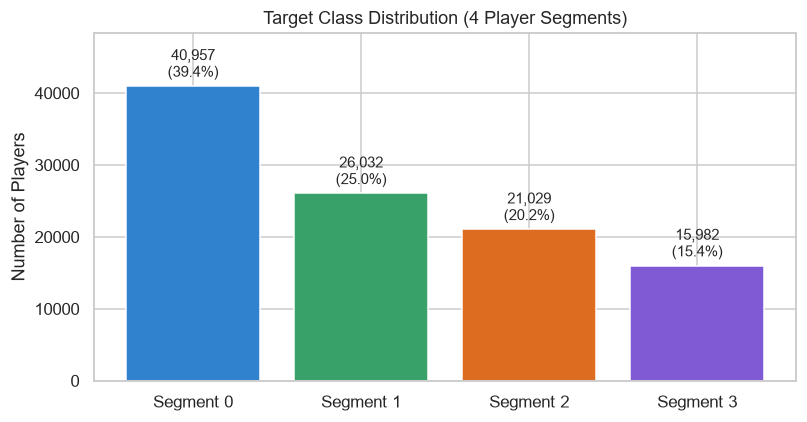

In [2]:
counts = pd.Series(y).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7.5, 4))
palette = ["#3182ce", "#38a169", "#dd6b20", "#805ad5"]
bars = ax.bar([f"Segment {k}" for k in counts.index], counts.values, color=palette)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width()/2, v + 700, f"{v:,}\n({v/len(y)*100:.1f}%)", ha="center", va="bottom", fontsize=10)
ax.set_title("Target Class Distribution (4 Player Segments)")
ax.set_ylabel("Number of Players")
ax.set_ylim(0, counts.max() * 1.18)
plt.tight_layout()
plt.show()

**Insight 1**:
- Segments are noticeably imbalanced (Segment 0 is the largest class, Segment 3 is the smallest).
- Under **Macro $F_1$**, each class contributes 25% of the score regardless of size, so standard `argmax(p)` under-predicts smaller classes.

**Decision**:
- Apply a **fixed-point affine Macro-$F_1$ decision rule** fitted strictly on OOF probabilities after blending.

## Step 2: Feature Signal vs. Noise (Numeric ANOVA F-Score & Categorical Cramér's V)

**What we check**: Which numeric and categorical columns genuinely distinguish the 4 segments?

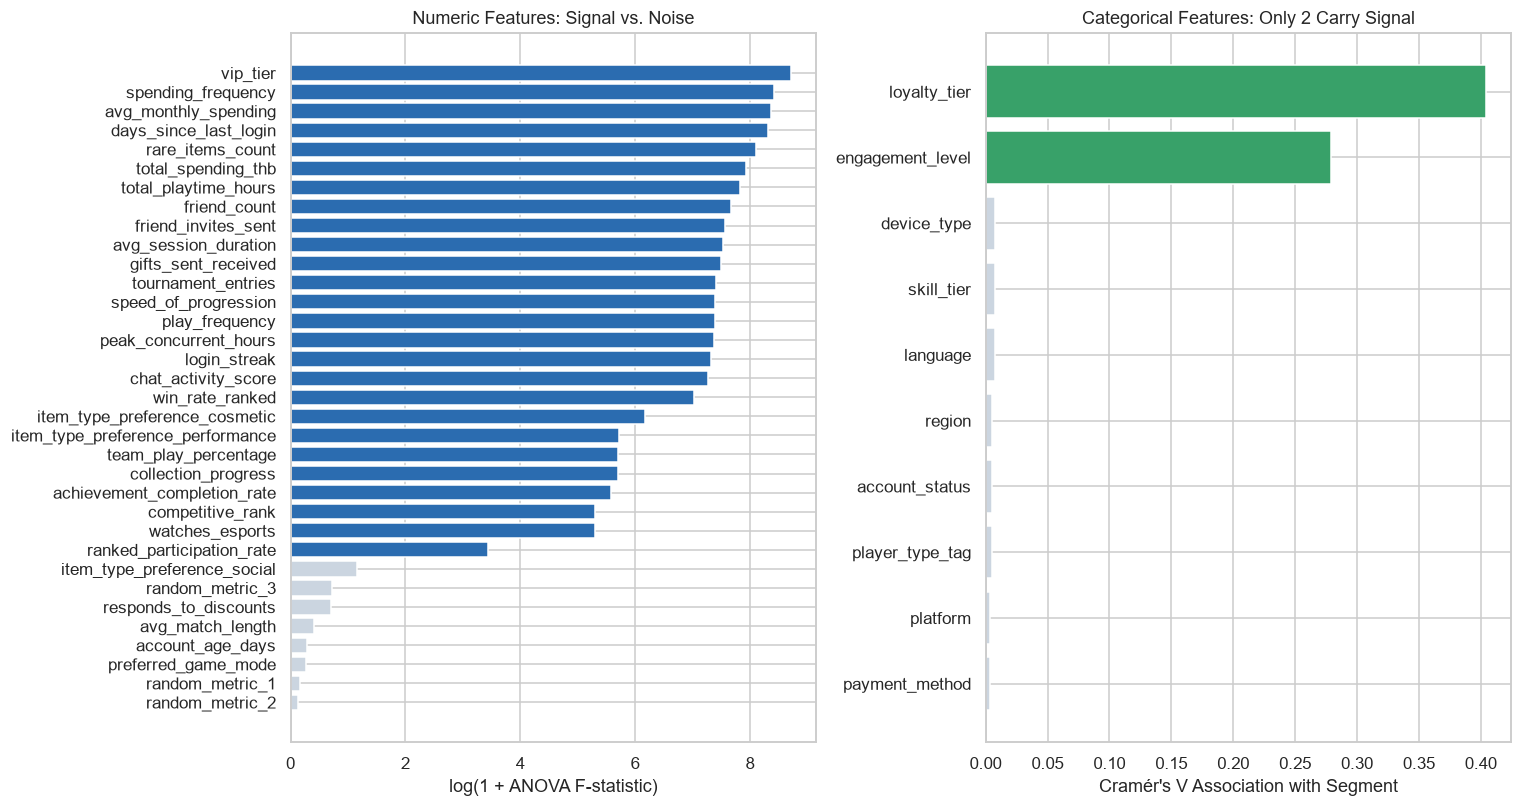

In [3]:
CATS = [c for c in tr.columns if (not pd.api.types.is_numeric_dtype(tr[c])) and c not in ("player_id", "segment")]
NUMS = [c for c in tr.columns if pd.api.types.is_numeric_dtype(tr[c]) and c != "segment"]

NOISE = [
    "random_metric_1", "random_metric_2", "random_metric_3", "account_age_days",
    "responds_to_discounts", "item_type_preference_social", "avg_match_length",
    "preferred_game_mode", "region", "platform", "device_type", "payment_method",
    "language", "account_status", "player_type_tag", "skill_tier"
]

# Numeric: log1p(ANOVA F-statistic)
f_scores = {}
for c in NUMS:
    groups = [tr.loc[y == k, c].dropna().values for k in range(K)]
    f_val, _ = f_oneway(*groups)
    f_scores[c] = np.log1p(max(f_val, 0.0))
f_df = pd.DataFrame({"feature": list(f_scores.keys()), "logF": list(f_scores.values())}).sort_values("logF")
f_df["is_noise"] = f_df["feature"].isin(NOISE)

# Categorical: Cramer's V
cv_scores = {}
for c in CATS:
    ct = pd.crosstab(tr[c].fillna("NA"), y)
    chi2 = chi2_contingency(ct)[0]
    n = ct.values.sum()
    cv_scores[c] = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
cv_df = pd.DataFrame({"feature": list(cv_scores.keys()), "cramers_v": list(cv_scores.values())}).sort_values("cramers_v")
cv_df["is_noise"] = cv_df["feature"].isin(NOISE)

fig, axes = plt.subplots(1, 2, figsize=(14, 7.5))

axes[0].barh(f_df["feature"], f_df["logF"], color=np.where(f_df["is_noise"], "#cbd5e0", "#2b6cb0"))
axes[0].set_xlabel("log(1 + ANOVA F-statistic)")
axes[0].set_title("Numeric Features: Signal vs. Noise")

axes[1].barh(cv_df["feature"], cv_df["cramers_v"], color=np.where(cv_df["is_noise"], "#cbd5e0", "#38a169"))
axes[1].set_xlabel("Cramér's V Association with Segment")
axes[1].set_title("Categorical Features: Only 2 Carry Signal")

plt.tight_layout()
plt.show()

**Insight 2**:
- Out of 10 categorical features, **only `engagement_level` and `loyalty_tier`** have meaningful association with `segment`; the other 8 categoricals (`region`, `platform`, `device_type`, etc.) have Cramér's $V \approx 0$.
- Among numeric features, 8 columns (including `random_metric_1..3`, `account_age_days`, `avg_match_length`, etc.) have $F \approx 1$ (zero signal).

**Decision**:
- Drop `player_id` and all **16 pure-noise features** immediately.

## Step 3: Within-Class Conditional Independence (Why Naive Bayes Excels)

**What we check**: Are the continuous signal features correlated *within* each segment, or only *across* segments?

Median |overall correlation|:      0.0324
Median |within-class correlation|: 0.0068


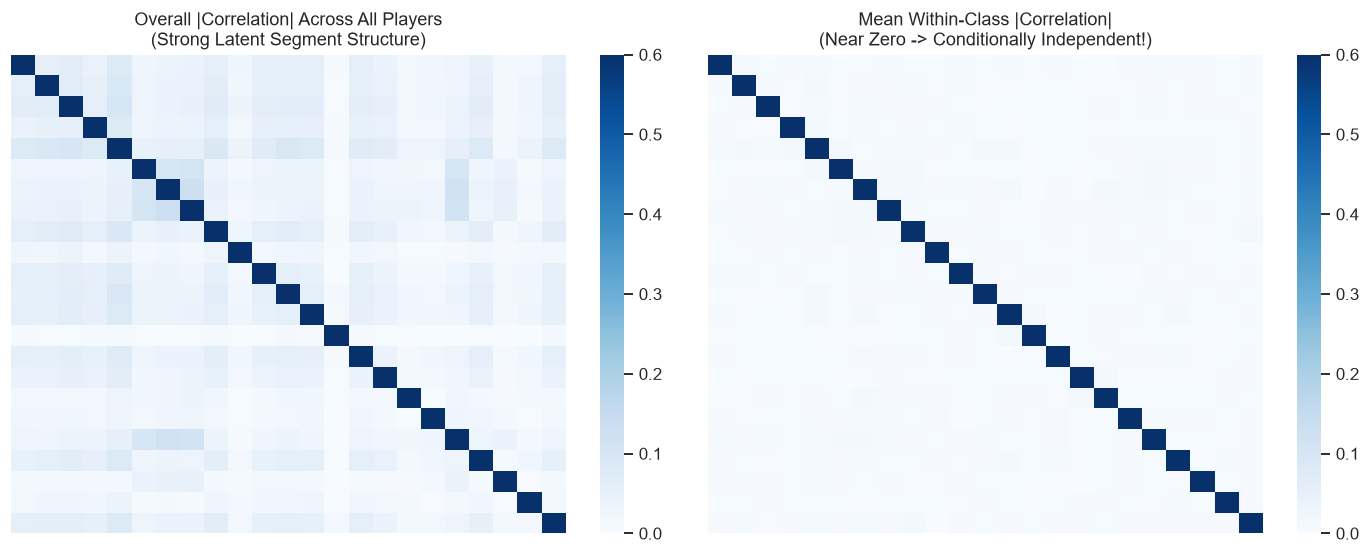

In [4]:
FEATS = [c for c in tr.columns if c not in ["player_id", "segment"] + NOISE]
DISC = [c for c in FEATS if (not pd.api.types.is_numeric_dtype(tr[c])) or tr[c].nunique() <= 12]
CONT = [c for c in FEATS if c not in DISC]

corr_overall = tr[CONT].corr().abs()
corr_within = sum(tr.loc[y == k, CONT].corr().abs() for k in range(K)) / K

iu = np.triu_indices(len(CONT), 1)
print(f"Median |overall correlation|:      {np.nanmedian(corr_overall.values[iu]):.4f}")
print(f"Median |within-class correlation|: {np.nanmedian(corr_within.values[iu]):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
sns.heatmap(corr_overall, ax=axes[0], cmap="Blues", vmin=0, vmax=0.6, xticklabels=False, yticklabels=False)
axes[0].set_title("Overall |Correlation| Across All Players\n(Strong Latent Segment Structure)")
sns.heatmap(corr_within, ax=axes[1], cmap="Blues", vmin=0, vmax=0.6, xticklabels=False, yticklabels=False)
axes[1].set_title("Mean Within-Class |Correlation|\n(Near Zero -> Conditionally Independent!)")
plt.tight_layout()
plt.show()

**Insight 3**:
- Overall correlations between features are strong because features co-vary across segments, **but once we condition on the segment, within-class correlations collapse to near zero** (median $|r| < 0.01$).
- Under conditional independence, **Naive Bayes is theoretically Bayes-optimal** — and unlike standard GBDTs, histogram Naive Bayes estimates smooth 1D class-conditional densities without fragmenting data across high-dimensional splits, while naturally marginalizing missing values.

**Decision**:
- Use **EM Label-Noise-Aware Histogram Naive Bayes** (with per-feature `(nbins, sigma)` tuned by inner-CV univariate log-loss) as our primary model (87% weight), blended with **Spline Logistic Regression** (8%) and **PyTorch MLP** (5%) for minor residual nonlinearities.

## Step 4: Segment Behavioral Profiles (2×2 Latent Structure)

**What we check**: How do the 4 segments differ across spending, playtime, and categorical tiers?

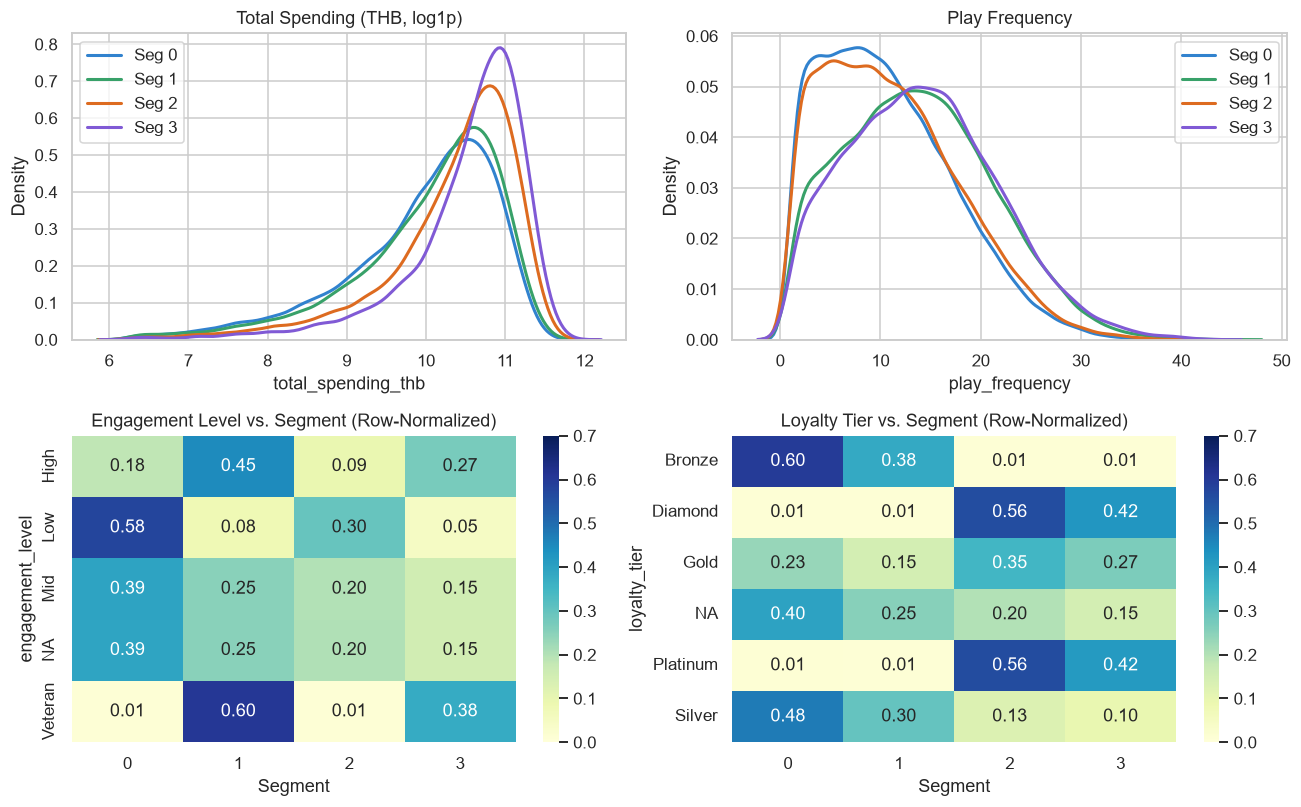

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))

for ax, col, title in [
    (axes[0, 0], "total_spending_thb", "Total Spending (THB, log1p)"),
    (axes[0, 1], "play_frequency", "Play Frequency"),
]:
    for k, clr in enumerate(["#3182ce", "#38a169", "#dd6b20", "#805ad5"]):
        v = np.log1p(tr.loc[y == k, col].clip(lower=0).dropna()) if "spending" in col else tr.loc[y == k, col].dropna()
        sns.kdeplot(v, ax=ax, label=f"Seg {k}", color=clr, lw=2)
    ax.set_title(title)
    ax.legend()

for ax, col, title in [
    (axes[1, 0], "engagement_level", "Engagement Level vs. Segment (Row-Normalized)"),
    (axes[1, 1], "loyalty_tier", "Loyalty Tier vs. Segment (Row-Normalized)"),
]:
    ct = pd.crosstab(tr[col].fillna("NA"), y, normalize="index")
    sns.heatmap(ct, annot=True, fmt=".2f", cmap="YlGnBu", ax=ax, vmin=0, vmax=0.7)
    ax.set_title(title)
    ax.set_xlabel("Segment")

plt.tight_layout()
plt.show()

**Insight 4**:
- The 4 segments form a clean **2×2 latent behavioral grid** (Engagement $\times$ Spending), with overlapping tails and a small fraction of symmetric label noise (~5–6%) visible in the cross-tabulations.

**Decision**:
- Model symmetric label noise explicitly using **15-iteration Expectation-Maximization (EM)** inside Histogram Naive Bayes.

---

## Summary: EDA Insights $\rightarrow$ Modeling Decisions (`task2.ipynb`)

| Step | EDA Finding | Decision in `task2.ipynb` |
| :--- | :--- | :--- |
| 1 | Imbalanced 4 classes evaluated by Macro $F_1$ | Apply fixed-point **affine Macro-$F_1$ decision rule** on OOF probabilities |
| 2 | 16 columns (8 categorical + 8 numeric) have zero class association | Drop `player_id` and all 16 noise columns |
| 3 | Within-class correlations collapse to near zero | Use **Histogram Naive Bayes** (87% weight) as primary model with NaN marginalization |
| 4 | 2×2 latent structure with symmetric label noise | Add **15-step EM label-noise estimation** + blend with Spline LR (8%) & PyTorch MLP (5%) |